<a href="https://colab.research.google.com/github/williamryanmckee-nwa/Deep-Learning/blob/main/Simple_Encoder_Step_by_Step.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simple Autoencoder - Step by Step

**Goal:** Train a small neural network to compress and reconstruct one MNIST digit image.

An autoencoder has two main parts:
- **Encoder:** converts an image into a smaller latent vector.
- **Decoder:** uses that vector to reconstruct the image.

We will use TensorFlow/Keras and MNIST (28 × 28 grayscale digit images). The notebook explains each step and displays the results.

## Step 1 Import libraries

TensorFlow builds and trains the neural network. <br>Matplotlib displays the original and reconstructed images.

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2 Load the MNIST dataset

Each image contains 28 × 28 pixels. <br>Pixel values range from 0 to 255. <br>We normalize them to 0 – 1 so training is easier.

For this beginner example, we will train using the MNIST training images, but later inspect just **one image**.

In [40]:
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values from 0–255 to 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)
print("One image shape:", x_train[0].shape)

Training images: (60000, 28, 28)
Test images: (10000, 28, 28)
One image shape: (28, 28)


Why discard the labels?

You usually see this syntax when training models that do not require known target outputs, such as:

• Autoencoders: Models trained to compress and then reconstruct the original input images (x).

• Generative Adversarial Networks (GANs): Models that learn to generate new, realistic images based solely on the distribution of the training images (x).

• Unsupervised Clustering: Algorithms (like K-Means) that group similar data points together without knowing pre-defined categories.

• Anomaly Detection: Systems trained to recognize "normal" data patterns so they can flag unusual variations later.


## Step 3 Look at one original image

An image is a 28 × 28 grid of numbers. Each number represents the brightness of a pixel.

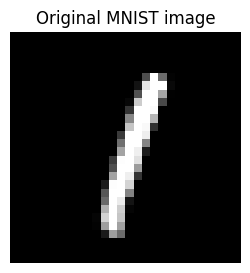

Pixel array shape: (28, 28)
First 5 pixel values in row 1: [0. 0. 0. 0. 0.]


In [41]:
image_index = 5
original_image = x_test[image_index]

plt.figure(figsize=(3, 3))
plt.imshow(original_image, cmap="gray")
plt.title("Original MNIST image")
plt.axis("off")
plt.show()

print("Pixel array shape:", original_image.shape)
print("First 5 pixel values in row 1:", original_image[0, :5])

Question :
What is 3x3?
cmap = gray?

https://search.r-project.org/CRAN/refmans/viridisLite/html/viridis.html

## Step 4 Flatten the image

The encoder will receive a vector of 784 numbers because 28 × 28 = 784.

Flattening changes the shape, not the pixel information.

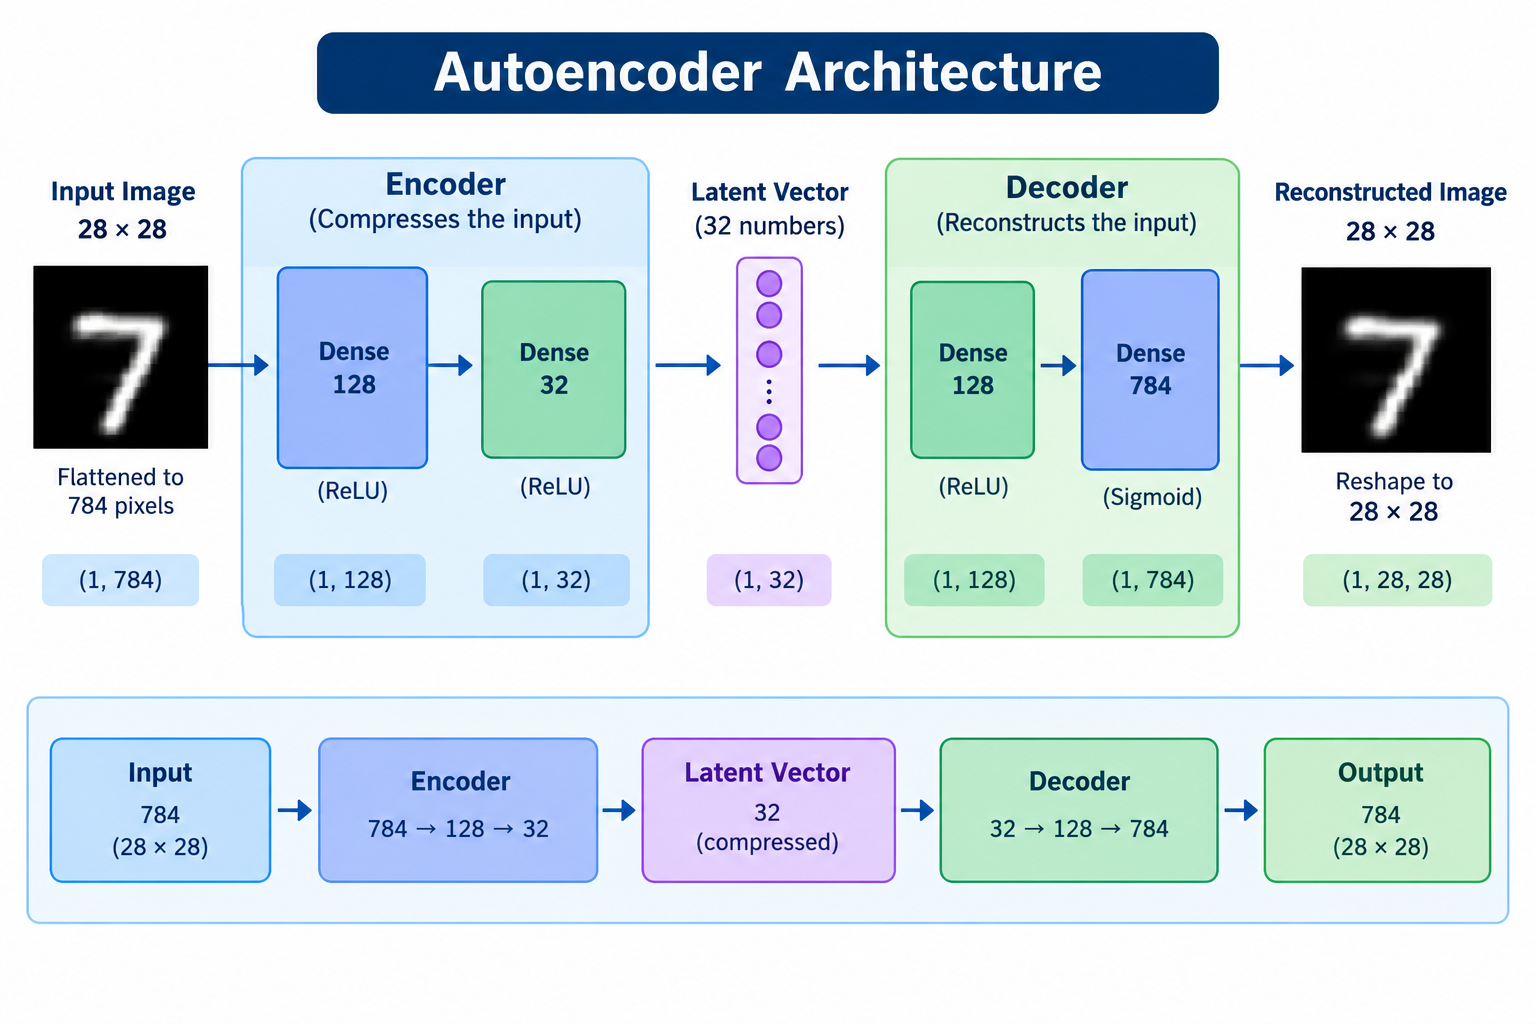

In [42]:
from IPython.display import Image
Image(filename="autoencoder1.png", width=200, height=200)

In [43]:
x_train_flat = x_train.reshape(-1, 28 * 28)
x_test_flat = x_test.reshape(-1, 28 * 28)

print("Before flattening:", x_train.shape)
print("After flattening:", x_train_flat.shape)
print("Pixels in one flattened image:", x_test_flat[image_index].shape[0])

Before flattening: (60000, 28, 28)
After flattening: (60000, 784)
Pixels in one flattened image: 784


## Step 5 Build the encoder and decoder

Architecture:
- **Input:** 784 pixel values
- **Encoder:** 784 → 128 → 32
- **Latent vector:** 32 numbers (compressed representation)
- **Decoder:** 32 → 128 → 784

The final 784 outputs are reshaped back into a 28 × 28 image.

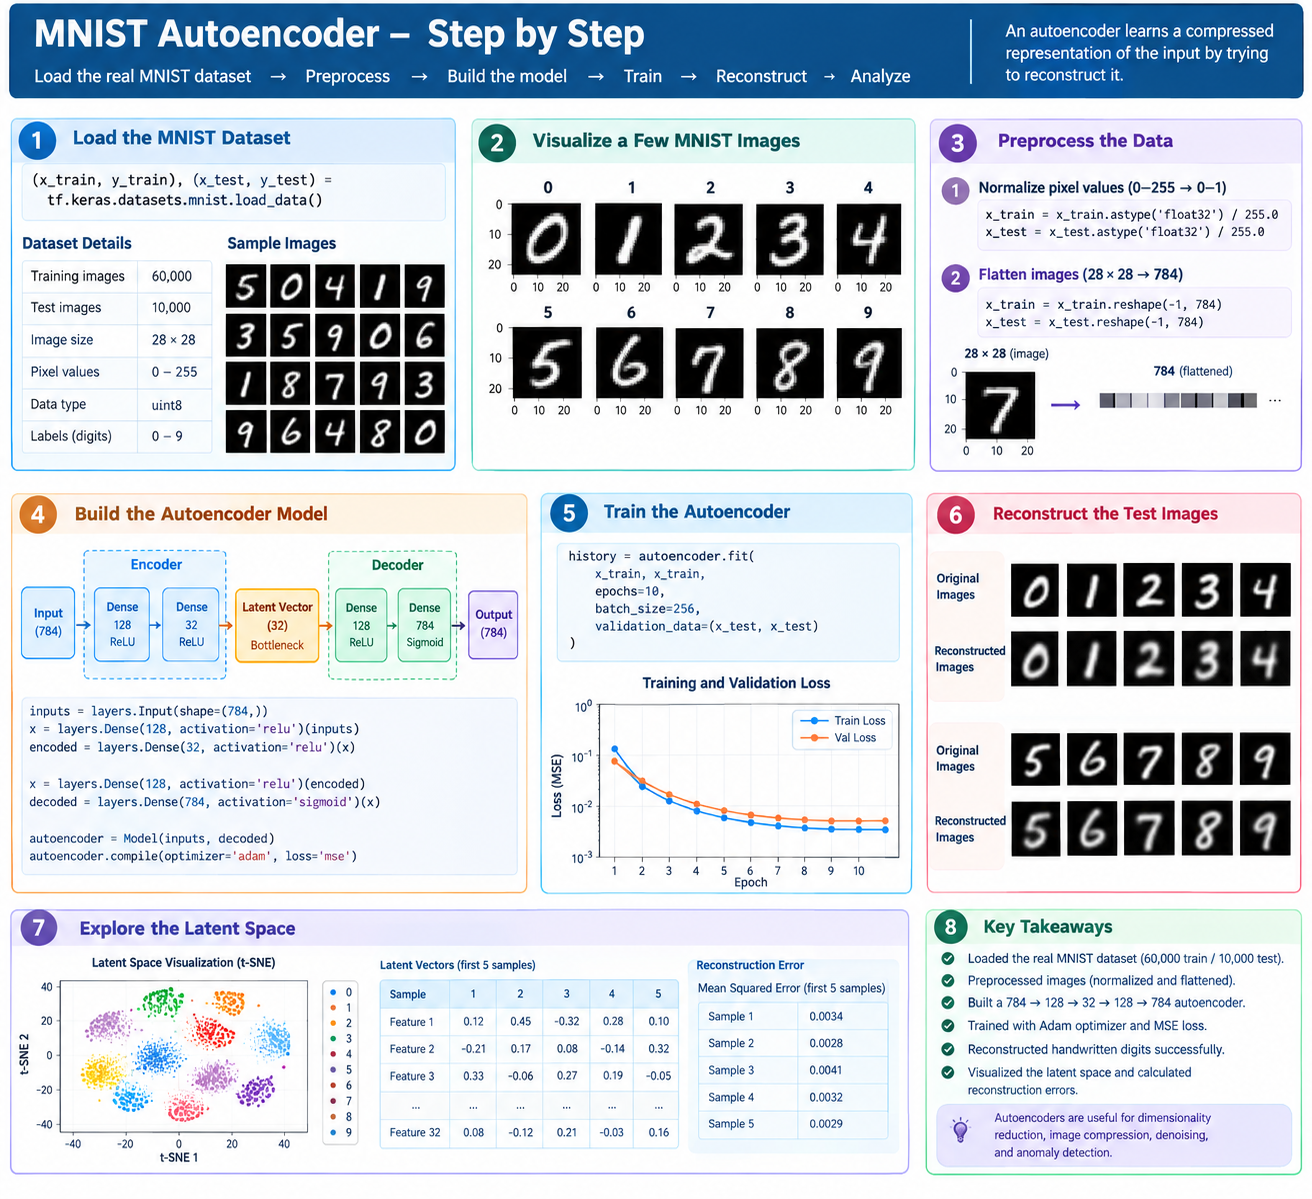

In [44]:
from IPython.display import Image
Image(filename="autoencoder2.png", width=700, height=500)

Question : what is the difference between Latent and Dense (hidden) layer?

Dense layer: The three-neuron mechanism that performs the calculations.
Latent vector: The three numbers produced by that mechanism.

In [45]:
input_layer = layers.Input(shape=(784,), name="image_pixels")

# Encoder: compress 784 values into 32 values
hidden_encoder = layers.Dense(128, activation="relu", name="encoder_hidden")(input_layer)
latent_vector = layers.Dense(32, activation="relu", name="latent_vector")(hidden_encoder)

# Decoder: reconstruct 784 pixel values from the 32-value vector
hidden_decoder = layers.Dense(128, activation="relu", name="decoder_hidden")(latent_vector)
reconstructed = layers.Dense(784, activation="sigmoid", name="reconstructed_pixels")(hidden_decoder)

autoencoder = Model(input_layer, reconstructed, name="simple_autoencoder")
encoder = Model(input_layer, latent_vector, name="encoder")

autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
autoencoder.summary()

Model: "simple_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_pixels (InputLayer)       │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_pixels (Dense)    │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

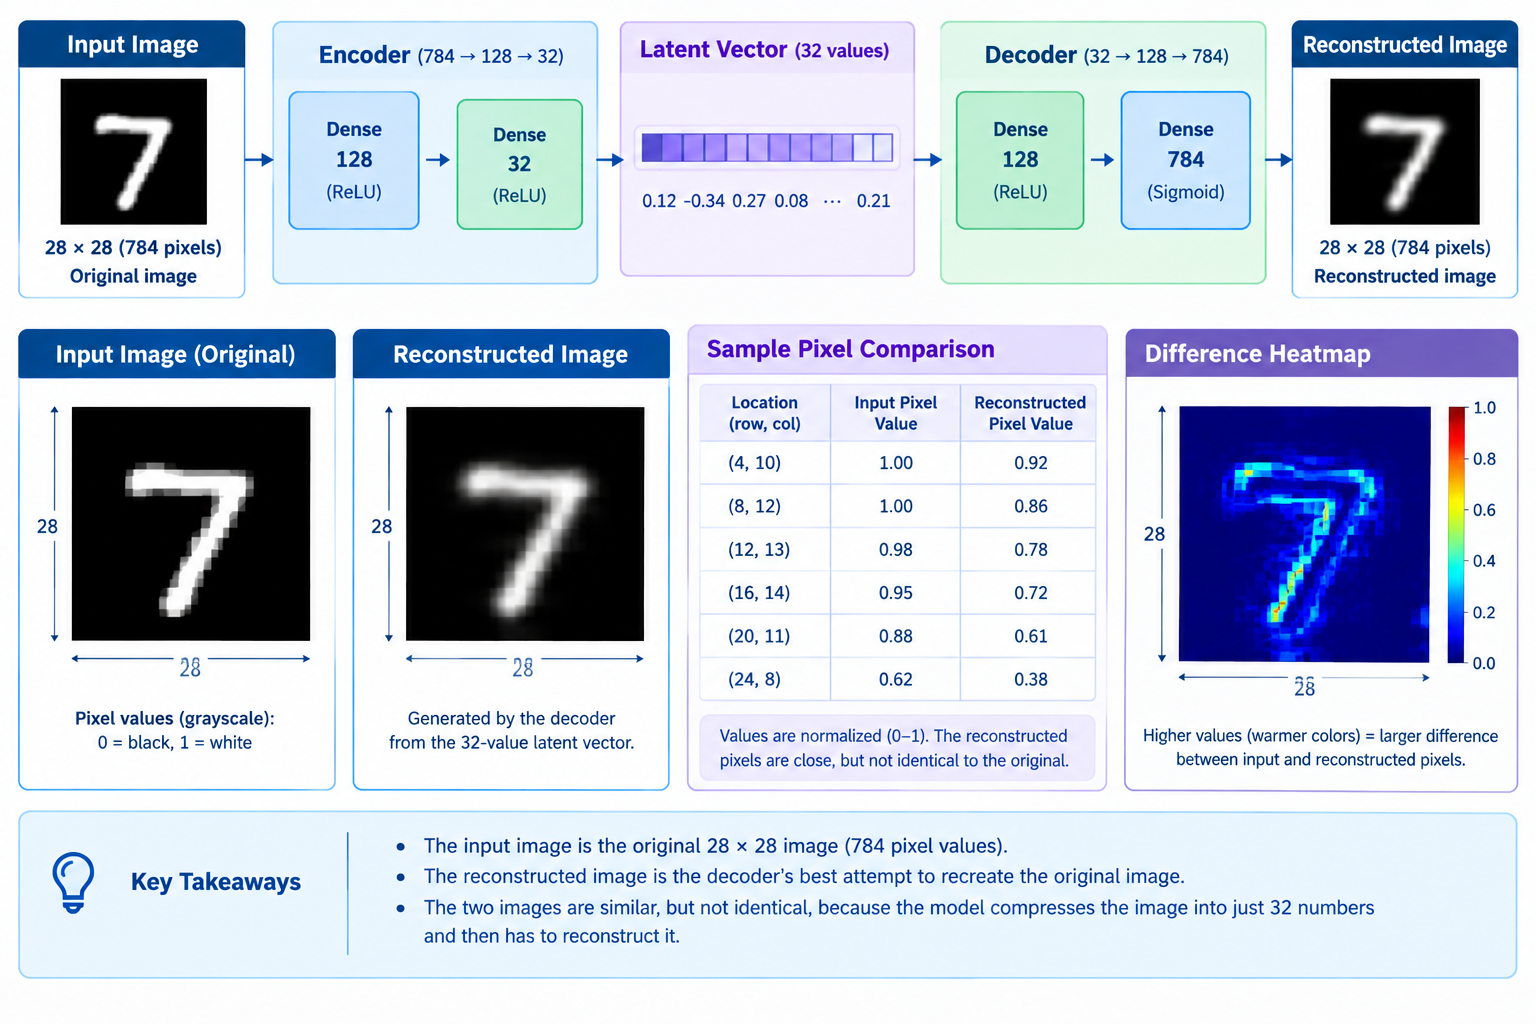

In [46]:
from IPython.display import Image
Image(filename="autoencoder3.png", width=700, height=500)

## Step 6 Train the autoencoder

The input and target are the **same images**. The model learns to reproduce its input.

- **Loss:** measures the difference between original and reconstructed pixels.
- **Epoch:** one pass through the training dataset.
- **Batch size:** number of images processed together before a weight update.

For a quick demonstration, train for 5 epochs. You can increase this to 10 or more for potentially better reconstructions.

In [47]:
history = autoencoder.fit(
    x_train_flat, x_train_flat,
    epochs=5,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.2367 - val_loss: 0.1544
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1370 - val_loss: 0.1220
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1167 - val_loss: 0.1097
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.1080 - val_loss: 0.1039
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.1030 - val_loss: 0.0999


## Step 7 Plot the training loss

A decreasing loss generally indicates that the model is learning to reconstruct the images.

Question : Seen or Unseen Data ? <br>
Training = Learn, Adjust the model's weights.
YES/NO ?

Validation = Tune, Choose model settings and monitor overfitting.
YES/NO ?

Testing = Evaluate, Measure final performance on unseen data.
YES/NO ?

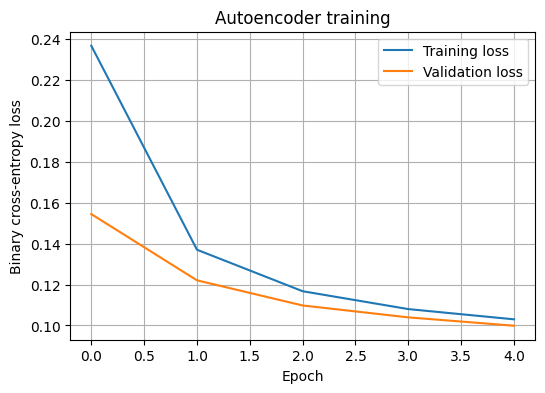

In [48]:
plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Autoencoder training")
plt.legend()
plt.grid(True)
plt.show()

## Step 8 Encode one image

Now pass just one image through the encoder. The output is a latent vector containing **32 numbers** instead of 784 pixel values.

The vector is a learned numerical representation; it usually does not look like an image.

In [49]:
one_image = x_test_flat[image_index:image_index + 1]  # shape (1, 784)
latent = encoder.predict(one_image, verbose=0)

print("Input shape:", one_image.shape)
print("Latent vector shape:", latent.shape)
print("The 32 latent values:")
print(np.round(latent[0], 3))

Input shape: (1, 784)
Latent vector shape: (1, 32)
The 32 latent values:
[11.322  0.     7.164  6.506  3.131  5.19   7.736  6.535  2.194  0.999
  6.104  9.678 12.238  0.     5.495  7.773 11.8    5.99   8.064  6.916
  8.682  9.871  3.336  1.843  8.099  5.493  7.917  2.295  5.32   4.302
  8.565  2.158]


## Step 9 Decode the latent vector

The decoder converts the 32 values back into 784 predicted pixel values, which we reshape into a 28 × 28 image.

In [50]:
decoded_flat = autoencoder.predict(one_image, verbose=0)
decoded_image = decoded_flat.reshape(28, 28)

print("Decoded vector shape:", decoded_flat.shape)
print("Reconstructed image shape:", decoded_image.shape)

Decoded vector shape: (1, 784)
Reconstructed image shape: (28, 28)


## Step 10 Compare original and reconstructed images

The reconstruction may be blurry or imperfect. The model is learning a compressed representation, so some detail can be lost.

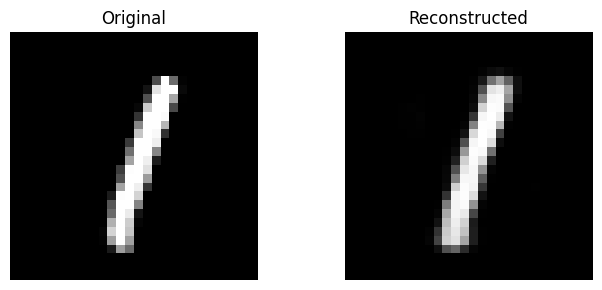

In [51]:
plt.figure(figsize=(7, 3))

plt.subplot(1, 2, 1)
plt.imshow(x_test[image_index], cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(decoded_image, cmap="gray")
plt.title("Reconstructed")
plt.axis("off")

plt.tight_layout()
plt.show()

## Step 11 Visualize the latent vector

This bar chart displays the 32 latent values. Each bar is one learned feature value. Individual values usually do not have a simple human-readable meaning.

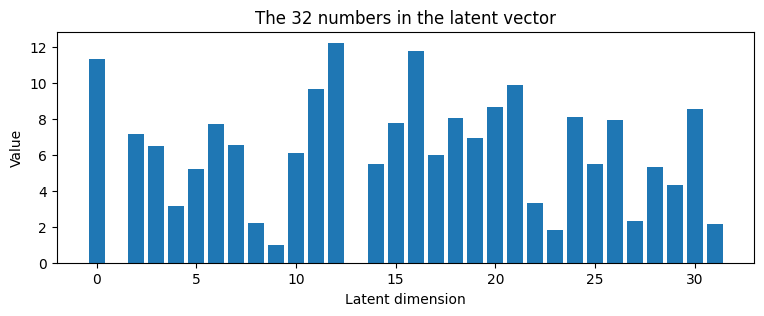

In [52]:
plt.figure(figsize=(9, 3))
plt.bar(range(32), latent[0])
plt.xlabel("Latent dimension")
plt.ylabel("Value")
plt.title("The 32 numbers in the latent vector")
plt.show()

## Step 12 Measure reconstruction error for this image

Mean squared error (MSE) compares each original pixel with its reconstructed counterpart. Lower is better, though it is only one measure of image quality.

In [53]:
mse = np.mean((one_image - decoded_flat) ** 2)
print(f"Reconstruction MSE for image {image_index}: {mse:.6f}")

Reconstruction MSE for image 5: 0.001655


## Summary

1. Loaded MNIST images and normalized pixel values.
2. Flattened each 28 × 28 image into 784 numbers.
3. Built an encoder that compresses 784 values to 32.
4. Built a decoder that reconstructs 784 values.
5. Trained the model to reproduce its own input.
6. Encoded and reconstructed one test image.

**Key idea:** the encoder compresses; the latent vector stores the compressed representation; the decoder reconstructs from it.

**Try next:** change `latent_vector` from 32 units to 16 or 8, retrain, and compare reconstruction quality. Smaller latent vectors mean stronger compression, but may lose more detail.